# MAT 422 - Section 3.7: Artificial Neural Networks

**Topics:** Mathematical formulation, Activation functions, Cost function, Backpropagation, Backpropagation algorithm

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1TsJ7H0cwORNeG5uH6Wl1zLyAhARqAUYI?usp=sharing)

In [80]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)


## Mathematical formulation

Neural networks use mathematical formulations to give us predicted probabilties, taking input vectors, transforming them through multiplicative weights and additive biases, and accounting for activation functions to give a desired output. In this case, we can see an example using sigmoid and tan hyperbolic functions.

In [81]:
# Define X, y, and rng values.
rng = np.random.default_rng(42)
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)
# Define sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
# Define 3 weights, one uniform bias.
W1 = rng.normal(scale=0.5, size=(2, 1))
b1 = np.zeros((1, 1))
W2 = rng.normal(scale=0.5, size=(1, 1))
W3 = rng.normal(scale=0.5, size=(1, 1))
# Define the forward functions, calculate the overall activation values
# and return three parameters a1, a2, and a3.
def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2
    a2 = np.tanh(z2)
    z3 = a2 @ W3
    a3 = sigmoid(z3)
    return a1, a2, a3
# Save a1 = h1, a2 = h2, and output = a3.
h1, h2, output = forward(X)
# Print out neural network parameters and layer transformations.
print("Neural Network Parameters\n")
print("W1 (Layer 1 Weights)\n", W1)
print("b1 (Layer 1 Biases)\n", b1)
print("W2 (Layer 2 Weights)\n", W2)
print("b2 (Layer 3 Weights)\n", W3)

print("\nLayer Transformations")
print("Hidden Layer 1 values:\n", h1)
print("Hidden Layer 2 values:\n", h2)
print("Output values:\n", output)

Neural Network Parameters

W1 (Layer 1 Weights)
 [[ 0.15236]
 [-0.51999]]
b1 (Layer 1 Biases)
 [[0.]]
W2 (Layer 2 Weights)
 [[0.37523]]
b2 (Layer 3 Weights)
 [[0.47028]]

Layer Transformations
Hidden Layer 1 values:
 [[ 0.     ]
 [-0.47769]
 [ 0.15119]
 [-0.35192]]
Hidden Layer 2 values:
 [[ 0.     ]
 [-0.17735]
 [ 0.05667]
 [-0.13129]]
Output values:
 [[0.5    ]
 [0.47916]
 [0.50666]
 [0.48457]]


## Activation functions

Activation functions calculates the sum of inputs, weighted, using a non-linear way to predict patterns in data analysis. In this example, one case of an activation function is an ReLU (Recitified Learning Unit), which gives the input if it is greater than 0 and returns otherwise.

In this example, we visually graph two different activation functions, the ReLU and Sigmoid functions, to show the differences in how these functions calculate for an neural network.

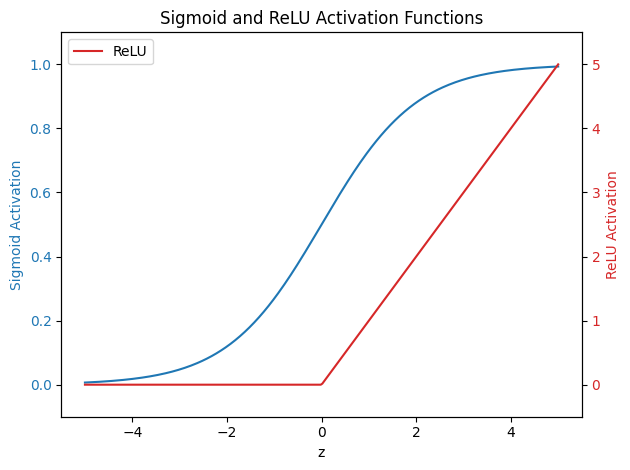

In [82]:
# Define ReLU Function
def relu(z):
    return np.maximum(0, z)
# Define Sigmoid Function
def sigmoid_activation(z):
    return 1 / (1 + np.exp(-z))
# Sigmoid Activation Function => Blue Graph
z = np.linspace(-5, 5, 300)
fig, ax1 = plt.subplots()
color = 'tab:blue'
ax1.set_xlabel('z')
ax1.set_ylabel('Sigmoid Activation', color=color)
ax1.plot(z, sigmoid_activation(z), color=color, label='Sigmoid')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(-0.1, 1.1)
# ReLU Activation Function => Red Graph
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('ReLU Activation', color=color)
ax2.plot(z, relu(z), color=color, label='ReLU')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(-0.5, 5.5)

plt.title('Sigmoid and ReLU Activation Functions')
plt.legend()
fig.tight_layout()
plt.show()


## Cost function

Cost functions, also known as loss functions, are functions that calculate how well or poor a neural network is performing, taking the difference between the predictive value and measured value. One example of a loss function is the binary cross-entropy loss function (BCE), which takes the normalized mean of predicted and binary labels to estimate the logarithmic model error.

In this case, we examine one such case of BCE to analyze target values and predicited probabilties.

In [83]:
def binary_cross_entropy(y_true, y_prob):
    y_prob = np.clip(y_prob, 1e-15, 1 - 1e-15)
    return -np.mean(y_true*np.log(y_prob) + (1-y_true)*np.log(1-y_prob))

# Unpack the 3 outputs returned by forward(X)
h1, h2, output = forward(X)
print("Initial binary cross-entropy =", binary_cross_entropy(y, output))
print("Target values:", y.ravel())
print("Initial predicted probabilities:", output.ravel())

Initial binary cross-entropy = 0.6928821351517547
Target values: [0. 1. 1. 0.]
Initial predicted probabilities: [0.5     0.47916 0.50666 0.48457]


## Backpropagation

Backpropagation involves a comparsion with the inital input and the expected output, adjusting the internal weight and bias of the neural network until the model achieves a high-performance, desired result. In this case, we demonstrate a specific case of backpropagation with a 10-layer forward and backward pass.

In [84]:
# Define Layers
layers = [4, 8, 8, 8, 16, 16, 8, 8, 8, 1]

weights = [np.random.randn(layers[i], layers[i+1]) * np.sqrt(2.0/layers[i]) for i in range(len(layers) - 1)]
biases = [np.zeros((layers[i], 1)) for i in range(1, len(layers))]
# Define Sigmoid function, derivative of sigmoid, and BCE.
def sigmoid(x):
  return 1 / (1 + np.exp(-np.clip(x, -500, 500)))
def sigmoid_derivative(x):
  return sigmoid(x) * (1 - sigmoid(x))
def BCE(y_true, y_pred):
  y_prob = np.clip(y_pred, 1e-15, 1 - 1e-15)
  return -np.mean(y_true*np.log(y_prob) + (1-y_true)*np.log(1-y_prob))
# Find X-values and y-value.
X = np.random.rand(1, 4)
y = np.array([[1]])
# Start 10-layer function process, with 9 transition parts.
print("START: 10-layer function.")
activations = [X]
for i in range(len(layers) - 1):
  a = np.dot(activations[-1], weights[i]) + biases[i].T
  z = sigmoid(a)
  activations.append(z)
output = activations[-1]
init_loss = BCE(y, output)

w_grad = [None] * (len(layers) - 1)
b_grad = [None] * (len(layers) - 1)

dA = - (y / output - (1 - y) / (1 - output))
dZ = dA * sigmoid_derivative(np.dot(activations[-2], weights[-1]) + biases[-1].T)

print("START: Backpropagation.")
for i in reversed(range((len(layers) - 1))):
  w_grad[i] = np.dot(activations[i].T, dZ)
  b_grad[i] = np.sum(dZ, axis=0, keepdims=True).T
  if i > 0:
    dA_previous = np.dot(dZ, weights[i].T)
    dZ = dA_previous * sigmoid_derivative(activations[i])
print("END: Finished Backpropagation.")
# Calculate final output and loss using learning rate:
learning_rate = 0.5
for i in range(len(layers) - 1):
  weights[i] -= learning_rate * w_grad[i]
  biases[i] -= learning_rate * b_grad[i]

new_activations = [X]
for i in range(len(layers) - 1):
  new_a = np.dot(new_activations[-1], weights[i]) + biases[i].T
  new_z = sigmoid(new_a)
  new_activations.append(new_z)
final_output = new_activations[-1]
final_loss = BCE(y, final_output)
print("END: 10-layer function.")
# Print out init and final loss.
print("ARE INPUTS EQUAL?")
print(f"Equal Inputs?", np.array_equal(X, activations[0]))
print("LOSS VALUES:")
print(f"Initial Loss: {init_loss:.5f}")
print(f"Final Loss: {final_loss:.5f}")
print("PREDICTED PROBABILITIES:")
print(f"Initial: {output.ravel()}")
print(f"Final: {final_output.ravel()}")

START: 10-layer function.
START: Backpropagation.
END: Finished Backpropagation.
END: 10-layer function.
ARE INPUTS EQUAL?
Equal Inputs? True
LOSS VALUES:
Initial Loss: 1.62408
Final Loss: 0.58732
PREDICTED PROBABILITIES:
Initial: [0.19709]
Final: [0.55581]


## Backpropagation algorithm

Previously, we demonstrated how backpropagation can track loss values for a 10-layer function. Now, we can use an algorithm, customizing learning rate and tracking losses to show how effective a model is, iteratively.

FINAL STATISTICS
Final probabilities:
 [[0.00746]
 [0.99973]
 [0.99982]
 [0.00015]]
Final predictions: [0 1 1 0]
Final losses: 0.0020217963228101273


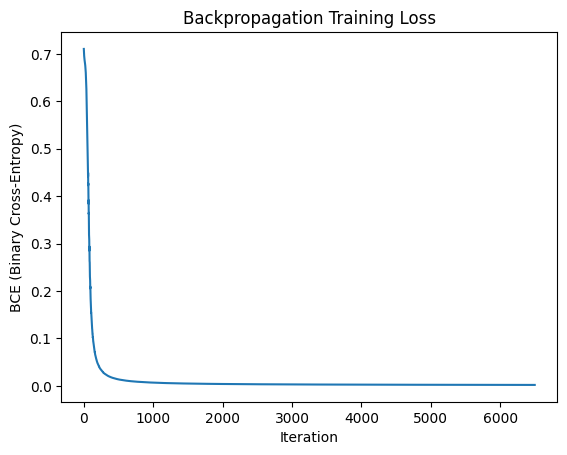

In [85]:
# X-value and y-value initalize
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)
# Initalize the input dimensions, hidden dimensions 1 and 2, and output dimensions
np.random.seed(42)
input_dim = 2
hidden_dim1 = 4
hidden_dim2 = 4
output_dim = 1
# Setup W1, b1, W2, b2, and W3, b3.
W1 = np.random.randn(input_dim, hidden_dim1) * np.sqrt(2.0 / input_dim)
b1 = np.zeros((1, hidden_dim1))

W2 = np.random.randn(hidden_dim1, hidden_dim2) * np.sqrt(2.0 / hidden_dim1)
b2 = np.zeros((1, hidden_dim2))

W3 = np.random.randn(hidden_dim2, output_dim) * np.sqrt(2.0 / hidden_dim2)
b3 = np.zeros((1, output_dim))
# Define activation functions and BCE loss.
def relu(x):
    return np.maximum(0, x)

def relu_derivative(a):
    return (a > 0).astype(float)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def binary_cross_entropy(y_true, y_prob):
    y_prob = np.clip(y_prob, 1e-15, 1 - 1e-15)
    return -np.mean(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))
# Define forward function.
def forward(X_input):
    a1 = relu(X_input @ W1 + b1)
    a2 = relu(a1 @ W2 + b2)
    a3 = sigmoid(a2 @ W3 + b3)
    return a1, a2, a3
# Define learning rate, and decay rate. Initalize the losses value.
initial_learning_rate = 0.3
decay_rate = 0.001
losses = []
# Iterate through 6.5K steps. Track changes in the activations, weights, and biases.
for step in range(6500):
    learning_rate = initial_learning_rate * (1 / (1 + decay_rate * step))

    a1, a2, a3 = forward(X)
    losses.append(binary_cross_entropy(y, a3))

    dz3 = (a3 - y) / len(X)
    dW3 = a2.T @ dz3
    db3 = dz3.sum(axis=0, keepdims=True)

    da2 = dz3 @ W3.T
    dz2 = da2 * relu_derivative(a2)
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)

    da1 = dz2 @ W2.T
    dz1 = da1 * relu_derivative(a1)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)

    W3 -= learning_rate * dW3
    b3 -= learning_rate * db3
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
# Given final predicitions and probabilties.
_, _, final_output = forward(X)
print("FINAL STATISTICS")
print("Final probabilities:\n", final_output)
print("Final predictions:", (final_output > 0.5).astype(int).ravel())
print("Final losses:", losses[-1])

plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("BCE (Binary Cross-Entropy)")
plt.title("Backpropagation Training Loss")
plt.show()